<a href="https://colab.research.google.com/github/krishnamaheshwaribdn-pixel/krishna_maheshwari_2503215300098_miniproject/blob/main/krishna_maheshwari_2503215300098_miniproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Exploratory Data Analysis: Retail Customer Sales**

Project: Understanding, cleaning and profiling retail customer sales data


---



1. Load the data and take a first look

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

df = pd.read_csv("retail_customer_sales_dataset.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data type"))
print("\nFirst five rows:")
display(df.head())
print("\nLast five rows:")
display(df.tail())

Dataset shape: (7084, 24)

Column names:
['Transaction_ID', 'Customer_ID', 'Order_Date', 'Delivery_Date', 'Age', 'Gender', 'Income', 'Region', 'State', 'City', 'Customer_Segment', 'Product_Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Payment_Method', 'Delivery_Mode', 'Customer_Rating', 'Satisfaction_Level', 'Returned']

Data types:


,Data type
Transaction_ID,object
Customer_ID,object
Order_Date,object
Delivery_Date,object
Age,float64
Gender,object
Income,float64
Region,object
State,object
City,object



First five rows:


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.00,Male,"62,828.52",West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,"1,811.40","1,204.47",606.93,Debit Card,Standard,3.00,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.00,Male,"50,952.64",North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,"14,309.96",0.18,"23,468.33","17,137.06","6,331.27",Credit Card,Standard,3.00,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.00,Male,"60,476.00",East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,"2,587.86","1,577.83","1,010.03",Debit Card,Express,3.00,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.00,Male,"41,516.94",West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.00,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.00,Female,"95,727.49",north,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,"10,542.13",0.21,"8,328.28","5,528.47","2,799.81",UPI,Express,1.00,Low,No



Last five rows:


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
7079,TXN201768,CUST10870,2024-10-22,2024-10-27,34.00,Male,"79,446.58",East,Odisha,Bhubaneswar,Corporate,Electronics,Laptop Stand,1,"5,395.38",0.09,"4,909.80","3,273.47","1,636.33",Net Banking,Express,2.00,Low,Yes
7080,TXN201737,CUST10314,2024-10-05,2024-10-14,50.00,Male,"21,796.92",East,West Bengal,Durgapur,Home Office,Clothing,Formal Shirt,3,"1,603.82",0.02,"4,715.23","2,923.68","1,791.55",Credit Card,Standard,4.00,High,No
7081,TXN203240,CUST10859,2024-06-04,2024-06-15,42.00,Male,"60,621.27",West,Gujarat,Surat,Consumer,Electronics,Laptop Stand,1,"11,519.59",0.22,"8,985.28","5,360.01","3,625.27",UPI,Standard,2.00,Medium,No
7082,TXN205305,CUST10829,2024-03-31,2024-04-08,32.00,Female,"42,178.47",South,Kerala,Kozhikode,Consumer,Clothing,Running Shoes,3,980.67,0.21,"2,324.19","1,812.17",512.02,UPI,Standard,4.00,High,No
7083,TXN204737,CUST10847,2024-10-18,2024-10-26,63.00,Male,"44,113.29",South,Kerala,Kozhikode,Consumer,Clothing,Denim Jacket,2,"3,727.59",0.30,"5,218.63","3,932.52","1,286.11",Debit Card,Standard,4.00,High,No


2. Data quality audit

In [ ]:
missing_audit = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean().mul(100).round(2)
}).sort_values("Missing_Count", ascending=False)

print("Missing-value audit")
display(missing_audit)
print("Exact duplicate rows:", df.duplicated().sum())

category_columns = ["Gender", "Region", "Customer_Segment", "Product_Category",
                    "Payment_Method", "Delivery_Mode", "Satisfaction_Level", "Returned"]

for column in category_columns:
    print("\n", column)
    display(df[column].value_counts(dropna=False).to_frame("Count"))

numeric_columns = ["Age", "Income", "Quantity", "Unit_Price", "Discount",
                   "Sales", "Cost", "Profit", "Customer_Rating"]
display(df[numeric_columns].describe().T)

for column in ["Order_Date", "Delivery_Date"]:
    print(column, "sample values:")
    display(df[column].dropna().astype(str).head(10))

print("Age below 0 or above 100:", ((df["Age"] < 0) | (df["Age"] > 100)).sum())
print("Discount outside 0 to 0.5:", ((df["Discount"] < 0) | (df["Discount"] > 0.5)).sum())

Missing-value audit


,Missing_Count,Missing_Percent
Customer_Rating,428,6.04
Income,253,3.57
Satisfaction_Level,179,2.53
Age,142,2.00
Delivery_Date,106,1.50
Discount,71,1.00
Order_Date,0,0.00
Transaction_ID,0,0.00
Region,0,0.00
Gender,0,0.00


Exact duplicate rows: 61

 Gender


,Count
Gender,
Female,3585
Male,3232
female,53
FEMALE,53
male,46
MALE,44
M,38
F,33



 Region


,Count
Region,
West,1783
East,1754
South,1741
North,1647
east,30
south,24
north,21
Sth,20
WEST,19


... (14 outputs left out)

,Order_Date
0,2023-12-19
1,2023-09-30
2,2023-01-12
3,2024-06-06
4,2024-09-23
5,2024-09-04
6,2023-10-23
7,2023-10-13
8,2023-06-22
9,2024-12-18


Delivery_Date sample values:


,Delivery_Date
0,2023-12-25
1,2023-10-04
2,2023-01-20
3,2024-06-10
4,2024-09-30
5,2024-09-15
6,2023-11-05
7,2023-10-14
8,2023-06-23
9,2024-12-23


Age below 0 or above 100: 6
Discount outside 0 to 0.5: 6


3. Cleaning decisions

In [ ]:
clean = df.copy()

for column in clean.select_dtypes(include="object").columns:
    clean[column] = clean[column].astype("string").str.strip()

clean["Gender"] = clean["Gender"].str.lower().replace({"m": "male", "f": "female"}).str.title()
clean["Region"] = clean["Region"].str.lower().replace({"sth": "south", "nort": "north"}).str.title()

for column in ["Customer_Segment", "Product_Category", "Product", "State", "City",
               "Payment_Method", "Delivery_Mode", "Satisfaction_Level", "Returned"]:
    clean[column] = clean[column].str.replace(r"\\s+", " ", regex=True).str.title()

for column in ["Order_Date", "Delivery_Date"]:
    clean[column] = pd.to_datetime(clean[column], format="mixed", errors="coerce")

clean = clean.drop_duplicates().copy()

invalid_age = ~clean["Age"].between(0, 100)
invalid_discount = ~clean["Discount"].between(0, 0.5)
clean.loc[invalid_age, "Age"] = np.nan
clean.loc[invalid_discount, "Discount"] = np.nan

for column in ["Quantity", "Unit_Price", "Sales", "Cost", "Profit"]:
    invalid = clean[column] <= 0 if column in ["Quantity", "Unit_Price"] else clean[column] < 0
    clean.loc[invalid, column] = np.nan

bad_delivery = (
    clean["Delivery_Date"].notna()
    & clean["Order_Date"].notna()
    & (clean["Delivery_Date"] < clean["Order_Date"])
)
clean.loc[bad_delivery, "Delivery_Date"] = pd.NaT

for column in ["Age", "Income", "Discount"]:
    clean[column] = clean[column].fillna(clean[column].median())

clean["Satisfaction_Level"] = clean["Satisfaction_Level"].fillna("Unknown")

print("Original shape:", df.shape)
print("Cleaned shape:", clean.shape)
print("Duplicates removed:", df.duplicated().sum())
print("Invalid ages flagged:", int(invalid_age.sum()))
print("Invalid discounts flagged:", int(invalid_discount.sum()))
print("Delivery dates earlier than order dates:", int(bad_delivery.sum()))
display(clean.isna().sum().to_frame("Missing after cleaning"))

clean.to_csv("cleaned_retail_customer_sales.csv", index=False)

Original shape: (7084, 24)
Cleaned shape: (7002, 24)
Duplicates removed: 61
Invalid ages flagged: 146
Invalid discounts flagged: 76
Delivery dates earlier than order dates: 55


,Missing after cleaning
Transaction_ID,0
Customer_ID,0
Order_Date,0
Delivery_Date,160
Age,0
Gender,0
Income,0
Region,0
State,0
City,0


4. Descriptive statistics

In [ ]:
key_numeric = ["Age", "Income", "Quantity", "Unit_Price", "Discount", "Sales", "Cost", "Profit"]

summary = clean[key_numeric].describe().T
summary["Mode"] = clean[key_numeric].mode().iloc[0]
summary["Variance"] = clean[key_numeric].var()
summary["IQR"] = clean[key_numeric].quantile(0.75) - clean[key_numeric].quantile(0.25)
summary["Skewness"] = clean[key_numeric].skew()
display(summary[["count", "mean", "50%", "Mode", "std", "Variance", "25%", "75%", "IQR", "min", "max", "Skewness"]].rename(columns={"50%": "Median", "25%": "Q1", "75%": "Q3"}))

,count,mean,Median,Mode,std,Variance,Q1,Q3,IQR,min,max,Skewness
Age,"7,002.00",36.07,36.00,36.00,10.31,106.29,29.00,43.00,14.00,18.00,72.00,0.28
Income,"7,002.00","54,890.83","49,015.27","49,015.27","36,692.01","1,346,303,325.39","37,308.81","64,787.64","27,478.83","15,000.00","1,750,890.41",17.94
Quantity,"7,002.00",3.01,3.00,2.00,1.41,1.99,2.00,4.00,2.00,1.00,10.00,0.73
Unit_Price,"7,002.00","4,520.23","2,262.50",122.04,"4,893.36","23,945,000.70",896.26,"7,247.03","6,350.77",51.53,"19,989.99",1.26
Discount,"7,002.00",0.20,0.18,0.18,0.12,0.01,0.11,0.27,0.16,0.00,0.50,0.65
Sales,"7,002.00","10,961.55","4,828.31",258.73,"14,546.96","211,613,932.12","1,815.69","14,087.69","12,271.99",28.70,"122,950.97",2.40
Cost,"7,002.00","7,372.05","3,230.78",217.28,"9,876.59","97,547,090.08","1,211.08","9,490.36","8,279.28",19.53,"81,532.80",2.47
Profit,"7,002.00","3,589.51","1,528.88",19.47,"4,927.33","24,278,589.88",574.27,"4,532.96","3,958.69",9.17,"47,233.61",2.59


5. Univariate analysis and outliers

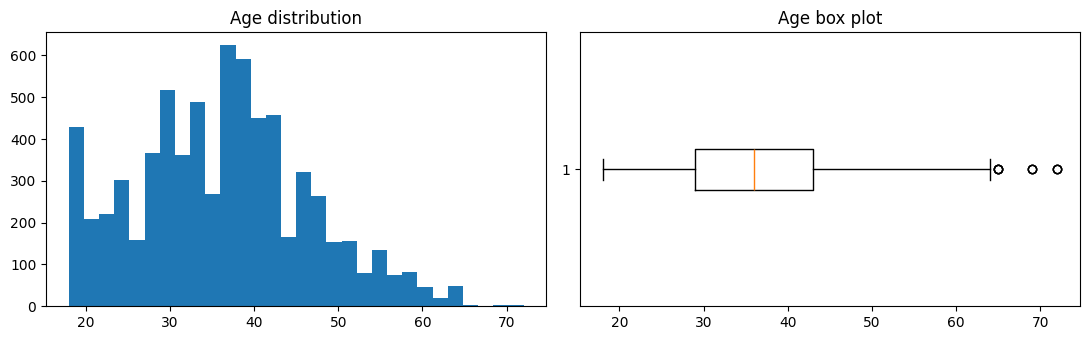

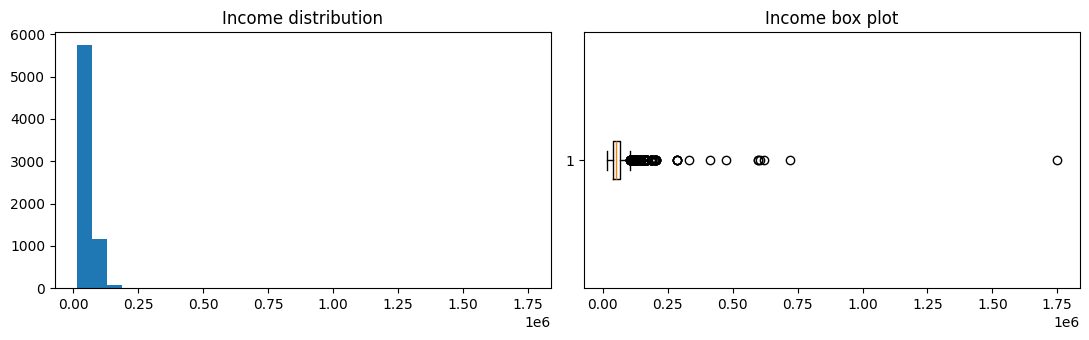

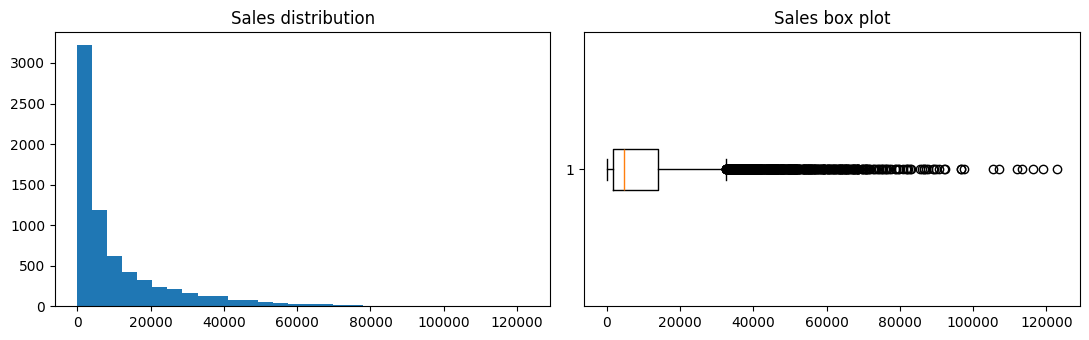

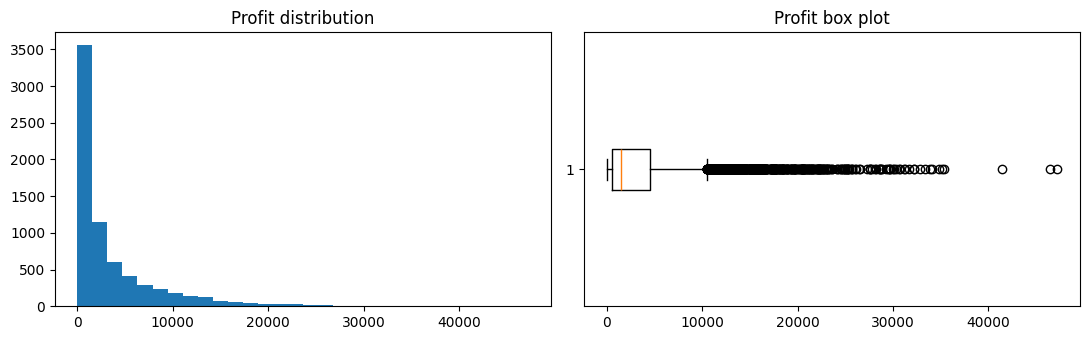

,Orders,Total_Sales,Average_Order_Value,Total_Profit
Region,,,,
East,1765,"20,018,192.35","11,341.75","6,607,664.00"
West,1798,"19,758,995.56","10,989.43","6,472,920.07"
South,1762,"18,900,922.76","10,726.97","6,180,931.86"
North,1677,"18,074,681.51","10,777.99","5,872,205.29"


In [ ]:
for column in ["Age", "Income", "Sales", "Profit"]:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].hist(clean[column].dropna(), bins=30)
    axes[0].set_title(f"{column} distribution")
    axes[1].boxplot(clean[column].dropna(), vert=False)
    axes[1].set_title(f"{column} box plot")
    plt.tight_layout()
    plt.show()

outlier_summary = []
for column in ["Sales", "Profit", "Age", "Income"]:
    q1 = clean[column].quantile(0.25)
    q3 = clean[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((clean[column] < lower) | (clean[column] > upper)).sum()
    outlier_summary.append([column, lower, upper, int(count), count / len(clean) * 100])

outlier_summary = pd.DataFrame(outlier_summary, columns=["Variable", "Lower_Bound", "Upper_Bound", "Outlier_Count", "Percent"])
display(region_summary)

In [ ]:
categorical_columns = ["Region", "Product_Category", "Customer_Segment"]

for column in categorical_columns:
    frequency = clean[column].value_counts(dropna=False).to_frame("Count")
    frequency["Proportion_Percent"] = frequency["Count"] / len(clean) * 100
    display(frequency)

,Count,Proportion_Percent
Region,,
West,1798,25.68
East,1765,25.21
South,1762,25.16
North,1677,23.95


,Count,Proportion_Percent
Product_Category,,
Electronics,1976,28.22
Grocery,1669,23.84
Clothing,1534,21.91
Furniture,979,13.98
Office Supplies,844,12.05


,Count,Proportion_Percent
Customer_Segment,,
Consumer,3841,54.86
Corporate,2115,30.21
Home Office,1046,14.94


6. Feature engineering

In [ ]:
clean["Profit_Margin"] = np.where(clean["Sales"] > 0, clean["Profit"] / clean["Sales"], np.nan)
clean["Delivery_Days"] = (clean["Delivery_Date"] - clean["Order_Date"]).dt.days
clean["Revenue_per_Customer"] = clean.groupby("Customer_ID")["Sales"].transform("sum")
clean["Order_Month"] = clean["Order_Date"].dt.to_period("M").astype(str)

display(clean[["Transaction_ID", "Profit_Margin", "Delivery_Days", "Revenue_per_Customer", "Order_Month"]].head())
clean.to_csv("cleaned_retail_customer_sales.csv", index=False)

,Transaction_ID,Profit_Margin,Delivery_Days,Revenue_per_Customer,Order_Month
0,TXN205933,0.34,6.00,"5,003.25",2023-12
1,TXN201247,0.27,4.00,"74,411.80",2023-09
2,TXN202714,0.39,8.00,"100,342.46",2023-01
3,TXN206797,0.37,4.00,"29,951.36",2024-06
4,TXN203937,0.34,7.00,"21,572.93",2024-09


7. Business questions using groupby

In [ ]:

import pandas as pd
import numpy as np

clean["Profit_Margin"] = np.where(
    clean["Sales"] > 0,
    clean["Profit"] / clean["Sales"],
    np.nan
)

clean["Order_Date"] = pd.to_datetime(
    clean["Order_Date"], errors="coerce"
)

clean["Delivery_Date"] = pd.to_datetime(
    clean["Delivery_Date"], errors="coerce"
)

clean["Delivery_Days"] = (
    clean["Delivery_Date"] - clean["Order_Date"]
).dt.days

region_summary = clean.groupby("Region").agg(
    Orders=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Order_Value=("Sales", "mean")
).round(2).sort_values("Total_Sales", ascending=False)

category_summary = clean.groupby("Product_Category").agg(
    Orders=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit_Margin=("Profit_Margin", "mean")
).round(2).sort_values("Total_Sales", ascending=False)

segment_summary = clean.groupby("Customer_Segment").agg(
    Orders=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Average_Order_Value=("Sales", "mean"),
    Total_Profit=("Profit", "sum")
).round(2).sort_values("Total_Sales", ascending=False)

payment_summary = clean.groupby("Payment_Method").agg(
    Orders=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Average_Order_Value=("Sales", "mean")
).round(2).sort_values("Orders", ascending=False)

delivery_summary = clean.groupby("Delivery_Mode").agg(
    Orders=("Transaction_ID", "count"),
    Average_Delivery_Days=("Delivery_Days", "mean"),
    Total_Sales=("Sales", "sum")
).round(2).sort_values("Orders", ascending=False)

print("\n1. REGION WISE SALES ANALYSIS\n")
print(region_summary.to_string())

print("\n2. PRODUCT CATEGORY ANALYSIS\n")
print(category_summary.to_string())

print("\n3. CUSTOMER SEGMENT ANALYSIS\n")
print(segment_summary.to_string())

print("\n4. PAYMENT METHOD ANALYSIS\n")
print(payment_summary.to_string())

print("\n5. DELIVERY MODE ANALYSIS\n")
print(delivery_summary.to_string())



1. REGION WISE SALES ANALYSIS

        Orders   Total_Sales  Total_Profit  Average_Order_Value
Region                                                         
East      1765 20,018,192.35  6,607,664.00            11,341.75
West      1798 19,758,995.56  6,472,920.07            10,989.43
South     1762 18,900,922.76  6,180,931.86            10,726.97
North     1677 18,074,681.51  5,872,205.29            10,777.99

2. PRODUCT CATEGORY ANALYSIS

                  Orders   Total_Sales  Total_Profit  Average_Profit_Margin
Product_Category                                                           
Electronics         1976 37,650,370.60 12,355,388.31                   0.33
Furniture            979 26,057,893.88  8,547,604.77                   0.33
Clothing            1534  7,792,470.09  2,523,697.59                   0.32
Grocery             1669  2,685,875.10    874,840.19                   0.32
Office Supplies      844  2,566,182.51    832,190.36                   0.33

3. CUSTOMER SEGMENT 

**8. Main findings and conclusion**
- The East region has the highest total sales in this dataset. Regional sales are relatively close, so the difference should be treated as a lead for further investigation rather than proof of a major performance gap.
- Electronics contributes the largest sales value. It is an important category to monitor for stock planning and supplier negotiations.
- Consumer customers account for the largest number of orders and the highest total sales among the three customer segments.
- Income and sales are right-skewed. A small group of high-value customers and orders raises the mean, so the median is also important when describing a typical customer or transaction.
- IQR flags several high sales and profit observations. These may be large genuine orders; transaction details should be checked before excluding them.
- Missing customer ratings are kept as missing because an order without a rating should not be treated as a low rating.
- Invalid ages, discounts and delivery dates were corrected or flagged using explicit business rules rather than being silently clipped.

This analysis gives a cleaner starting point for dashboards and later statistical work. It does not establish causation, and the business recommendations should be checked against operational context.
